# Домашняя работа №3
## Полный цикл ML-проекта: от "грязных" данных до сравнения моделей классификации
### 1. Постановка задачи
#### 1.1. Бизнес-контекст
**Задача:**
Предсказать, заключит ли клиент договор о срочном вкладе (переменная y).

**Датасет:**
Данные связаны с кампаниями прямого маркетинга одного португальского банковского учреждения.  Маркетинговые кампании проводились с помощью телефонных звонков.  Часто требовалось несколько обращений к одному и тому же клиенту, чтобы выяснить, будет ли он оформлять продукт (срочный банковский вклад) («да») или нет («нет»).  

**Признаки:**

- **Числовые**: age, balance, duration, campaign, pdays, previous

- **Категориальные**: job, marital, education, poutcome, contact

- **Бинарные**: default, housing, loan

- **Дата**: day_of_week, month, 

- **Целевая переменная**: y (Бинарная)

**Особенность датасета:** Изначально данные относительно чистые, что делает его идеальным для учебной задачи. Для придания ему более "реального" характера мы искусственно внесём в них проблемы.

## 2. Создание учебного «грязного» датасета
### 2.1. Технология создания
На этом этапе мы:

1. Загружаем исходный датасет.
2. Искусственно вносим пропуски (5–7%) в выбранные признаки.
3. Создаём дубликаты записей (примерно 3–5% от объёма).
4. Добавляем выбросы в числовые признаки.

# Описание числовых данных: age, balance, duration, campaign, pdays, previous
- **age** - Возраст человека
- **balance** - Остаток денег на счетах клиента в этом банке
- **duration** - Длительность последнего звонка в секундах
- **campaign** - Количество контактов во время этой кампании
- **pdays** - количество дней с последнего контакта предыдущей кампании
- **previous** - количество контактов до этой кампании

# Описание категориальных данных: job, marital, education, poutcome, contact
- **job** - Кем человек работает
- **marital** -Семейное положение
- **education** - Ступень образования
- **poutcome** - Результат предыдущей кампании
- **contact** - Тип связи с клиентом

# Описание бинарных данных: default, housing, loan
- **default** - Наличие кредитного дефолта (просроченной задолженности)
- **housing** - Наличие кредита на жилье (ипотеки)
- **loan** - Наличие потребительского кредита

# Описание временных признаков: day_of_week, month
- **day_of_week** - День недели последнего контакта
- **month** - Месяц последнего контакта в году

# Описание целевой переменной: y
- **y** - Оформил ли клиент срочный вклад (бинарная: 'yes' или 'no')

### 2.2. Код на `phyton` для создания "грязного" датасета
**Подключаем необходимые библиотеки**

In [1]:
import pandas as pd
import numpy as np

**Загружаем исходный "правильный" датасет `Bank Marketing`**

In [2]:
df = pd.read_csv('bank-full.csv', sep=';')
print(f"Исходный размер датасета: {df.shape}")
print(f"Колонки: {list(df.columns)}")
print(f"\nРаспределение целевой переменной:")
print(df['y'].value_counts())
print(df['y'].value_counts()/len(df))

Исходный размер датасета: (45211, 17)
Колонки: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Распределение целевой переменной:
y
no     39922
yes     5289
Name: count, dtype: int64
y
no     0.883015
yes    0.116985
Name: count, dtype: float64


Видно, что данные очень не сбалансированы, поэтому нужно будет с этим что-то делать в будущем.

**Искусственно формируем пропуски в 5%-7% в некоторые признаки**

In [3]:
np.random.seed(124)

def introduce_missing_values(dataframe, columns, missing_fraction=0.06):
    df_copy = dataframe.copy()
    n_rows = len(df_copy)
    n_missing = int(n_rows * missing_fraction)
    
    for col in columns:
        missing_indices = np.random.choice(n_rows, size=n_missing, replace=False)
        df_copy.loc[missing_indices, col] = np.nan
        print(f"  Внесено {n_missing} пропусков в колонку '{col}' ({missing_fraction*100:.0f}%)")
    return df_copy
columns_with_missing = ['age', 'balance', 'job', 'marital']

print("\n=== Внесение пропусков ===")
df_dirty = introduce_missing_values(df, columns_with_missing, missing_fraction=0.06)


=== Внесение пропусков ===
  Внесено 2712 пропусков в колонку 'age' (6%)
  Внесено 2712 пропусков в колонку 'balance' (6%)
  Внесено 2712 пропусков в колонку 'job' (6%)
  Внесено 2712 пропусков в колонку 'marital' (6%)


Чтобы задача стала похожа на реальную жизнь, мы специально испортили данные, добавили пропуски (NaN) в 4 важных колонок. В каждой примерно по 6% пропущенных значений.
Чтобы было схоже с реальной жизнью где кто-то забыл указать возраст, кто-то не захотел говорить о работе. Теперь модели придётся учиться работать с такими пустотами и заполнять их чем-то разумным.

**Создаём дубликаты записей**

In [4]:
def introduce_duplicates(dataframe, duplicate_fraction=0.04):
    n_duplicates = int(len(dataframe) * duplicate_fraction)
    
    duplicate_indices = np.random.choice(len(dataframe), size=n_duplicates, replace=False)
    duplicates = dataframe.iloc[duplicate_indices].copy()
    
    df_with_duplicates = pd.concat([dataframe, duplicates], ignore_index=True)
    
    print(f"  Создано {n_duplicates} дубликатов записей")
    print(f"  Новый размер датасета: {df_with_duplicates.shape}")
    
    return df_with_duplicates

print("\n=== Создание дубликатов ===")
df_dirty = introduce_duplicates(df_dirty, duplicate_fraction=0.04)



=== Создание дубликатов ===
  Создано 1808 дубликатов записей
  Новый размер датасета: (47019, 17)


Искусственно добавили 4% копий и из-за этого для модели теперь будет слложнее определить закономерности. 

**Добавляем выбросы в числовые признаки**

In [5]:
def introduce_outliers(dataframe, columns, outlier_fraction=0.02, multiplier=10):
    df_copy = dataframe.copy()
    n_rows = len(df_copy)
    n_outliers = int(n_rows * outlier_fraction)
    
    for col in columns:
        outlier_indices = np.random.choice(n_rows, size=n_outliers, replace=False)
        multipliers = np.random.uniform(multiplier/2, multiplier, size=n_outliers)
        df_copy.loc[outlier_indices, col] = df_copy.loc[outlier_indices, col] * multipliers
        print(f"  Внесено {n_outliers} выбросов в колонку '{col}'")
    
    return df_copy

numeric_outlier_columns = ['age', 'balance']

print("\n=== Внесение выбросов ===")
df_dirty = introduce_outliers(df_dirty, numeric_outlier_columns, outlier_fraction=0.001, multiplier=5)


=== Внесение выбросов ===
  Внесено 47 выбросов в колонку 'age'
  Внесено 47 выбросов в колонку 'balance'


Теперь в данных есть выбросы что также ухудшит для нас ситуацию.

**Сохраняем полученный "грязный" датасет**

In [6]:
print("\n=== Итоговый учебный датасет ===")
print(f"Размер: {df_dirty.shape}")
print(f"Пропуски в датасете:\n{df_dirty.isnull().sum()[df_dirty.isnull().sum() > 0]}")
print(f"Количество полных дубликатов: {df_dirty.duplicated().sum()}")

df_dirty.to_csv('bank-full-dirty.csv', index=False)
print("\nДатасет сохранён в 'bank-full-dirty.csv'")

print("\nПервые 5 строк учебного датасета:")
print(df_dirty.head())


=== Итоговый учебный датасет ===
Размер: (47019, 17)
Пропуски в датасете:
age        2811
job        2825
marital    2824
balance    2811
dtype: int64
Количество полных дубликатов: 1799

Датасет сохранён в 'bank-full-dirty.csv'

Первые 5 строк учебного датасета:
    age           job  marital  education default  balance housing loan  \
0  58.0    management  married   tertiary      no   2143.0     yes   no   
1  44.0    technician      NaN  secondary      no      NaN     yes   no   
2  33.0  entrepreneur  married  secondary      no      NaN     yes  yes   
3  47.0   blue-collar  married    unknown      no   1506.0     yes   no   
4  33.0       unknown   single    unknown      no      1.0      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome   y  
0  unknown    5   may       261         1     -1         0  unknown  no  
1  unknown    5   may       151         1     -1         0  unknown  no  
2  unknown    5   may        76         1     -1         0  unk

Итоговый датасет содержит 47019 строк и 17 столбцов. Видны все махинации которые мы делали после загрузки датасета.

## 3. Полный разведочный анализ данных (EDA)
### 3.1. Технология проведения EDA
Будем выполнять EDA  по следующему алгоритму:
1. Первичный осмотр: размер, типы, первые строки.
2. Анализ пропусков: визуализация и принятие решения.
3. Анализ дубликатов: обнаружение и удаление.
4. Вычисление описательных статистик: для числовых и категориальных признаков.
5. Визуализация: гистограммы, boxplots, bar plots, heatmap корреляций.
6. Обнаружение выбросов: с помощью IQR.
7. Формулировка выводов.

### 3.2. Код EDA (раведочного анализа данных)

Загрузка необходимых библиотек и настройка

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

Загрузка библиотек необходимых и настройка стиля визуализации как в лабораторной работе.

**Загрузка данных и их первичный осмотр**

In [8]:
df = pd.read_csv('bank-full-dirty.csv')

print("     ---  Проведение разведочного анализа данных  ---")
print("\n--- 1. Первичный осмотр данных ---")
print(f"Размер датасета: {df.shape}")
print(f"\nТипы данных:\n{df.dtypes}")
print(f"\nПервые 5 строк:\n{df.head()}")

     ---  Проведение разведочного анализа данных  ---

--- 1. Первичный осмотр данных ---
Размер датасета: (47019, 17)

Типы данных:
age          float64
job           object
marital       object
education     object
default       object
balance      float64
housing       object
loan          object
contact       object
day            int64
month         object
duration       int64
campaign       int64
pdays          int64
previous       int64
poutcome      object
y             object
dtype: object

Первые 5 строк:
    age           job  marital  education default  balance housing loan  \
0  58.0    management  married   tertiary      no   2143.0     yes   no   
1  44.0    technician      NaN  secondary      no      NaN     yes   no   
2  33.0  entrepreneur  married  secondary      no      NaN     yes  yes   
3  47.0   blue-collar  married    unknown      no   1506.0     yes   no   
4  33.0       unknown   single    unknown      no      1.0      no   no   

   contact  day month  durat

Видно, что некоторые данные закодированы не совсем верно, к примеру, age у нас float, однако должно быть int. Хотя это не так важно так как в данных у нас просто у каждого человека age представлен в виде ff.0 поэтому для предсказания другая кодировка не повлияет.

**Анализ пропусков**

--- 2. Анализ пропусков ---
         Количество пропусков  Доля (%)
age                      2811      5.98
job                      2825      6.01
marital                  2824      6.01
balance                  2811      5.98


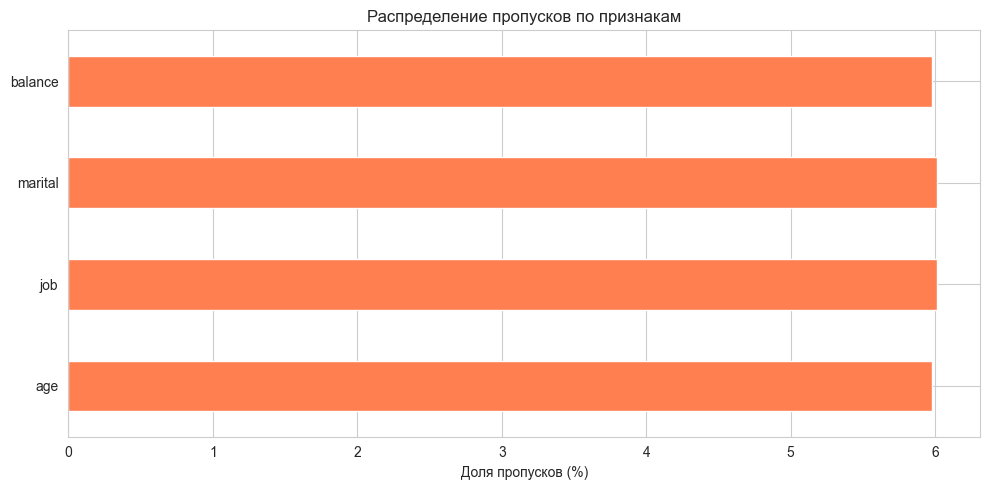

In [9]:
print("--- 2. Анализ пропусков ---")

missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({
    'Количество пропусков': missing,
    'Доля (%)': missing_pct.round(2)
})
missing_df = missing_df[missing_df['Количество пропусков'] > 0]
print(missing_df)

fig, ax = plt.subplots(figsize=(10, 5))
missing_df['Доля (%)'].plot(kind='barh', color='coral', ax=ax)
ax.set_xlabel('Доля пропусков (%)')
ax.set_title('Распределение пропусков по признакам')
plt.tight_layout()
plt.show()

Как и должно было быть, у нас пропуски в 4 признаках.

**Анализ дубликатов**

In [10]:
print("---3. Анализ дубликатов ---")

n_duplicates = df.duplicated().sum()
print(f"Количество полных дубликатов: {n_duplicates}")
print(f"Доля дубликатов: {n_duplicates / len(df) * 100:.2f}%")

df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Размер после удаления дубликатов: {df_clean.shape}")


---3. Анализ дубликатов ---
Количество полных дубликатов: 1799
Доля дубликатов: 3.83%
Размер после удаления дубликатов: (45220, 17)


Дубликаты там, где мы их поставили. Мы удалили дубликаты.

In [11]:
print("--- 4. Описательные статистики для числовых признаков ---")

numeric_cols = ['age', 'balance', 'duration', 'campaign', 
                'pdays', 'previous']
print(df_clean[numeric_cols].describe().round(2))

print("\nАсимметрия (Skewness):")
print(df_clean[numeric_cols].skew().round(3))
print("\nЭксцесс (Kurtosis):")
print(df_clean[numeric_cols].kurtosis().round(3))


--- 4. Описательные статистики для числовых признаков ---
            age    balance  duration  campaign     pdays  previous
count  42507.00   42508.00  45220.00  45220.00  45220.00  45220.00
mean      41.06    1370.86    258.18      2.76     40.19      0.58
std       11.44    3092.21    257.59      3.10    100.12      2.30
min       18.00   -8019.00      0.00      1.00     -1.00      0.00
25%       33.00      72.00    103.00      1.00     -1.00      0.00
50%       39.00     448.00    180.00      2.00     -1.00      0.00
75%       48.00    1431.00    319.00      3.00     -1.00      0.00
max      265.63  102127.00   4918.00     63.00    871.00    275.00

Асимметрия (Skewness):
age          2.382
balance      8.445
duration     3.144
campaign     4.899
pdays        2.616
previous    41.850
dtype: float64

Эксцесс (Kurtosis):
age           26.947
balance      141.316
duration      18.145
campaign      39.251
pdays          6.937
previous    4507.653
dtype: float64


- Видно, что большая асимметрия у balance,previous, campaign. Это говорит нам о том, что у этих признаков очень сильные выбросы. Однако, для итоговых моделей нужно будет оценить важность признаков и увидеть коэффициент корреляции с другими признакми и с целевой переменной, потому что наврятли все 16 признаков буду сильно влиять на целевую переменную.
- эксцесс почти у всех положительный большой, это значит что почти везде есть выбросы.
- Помимо этого нужно что-то делать с выбросами, но это посмотрим после более детального анализа.

**Анализ категориальных признаков**

In [12]:
print("--- 5. Частотный анализ категориальных признаков ---\n")

cat_cols = ['job', 'marital', 'education', 'contact', 'poutcome']

for col in cat_cols:
    summary = pd.DataFrame({
        'Количество': df_clean[col].value_counts(),
        'Доля (%)': (df_clean[col].value_counts(normalize=True) * 100).round(1)
    })
    print(f"Признак: {col}")
    display(summary)


--- 5. Частотный анализ категориальных признаков ---

Признак: job


,Количество,Доля (%)
job,,
blue-collar,9156,21.5
management,8870,20.9
technician,7153,16.8
admin.,4850,11.4
services,3925,9.2
retired,2142,5.0
self-employed,1480,3.5
entrepreneur,1390,3.3
unemployed,1220,2.9


Признак: marital


,Количество,Доля (%)
marital,,
married,25578,60.2
single,12021,28.3
divorced,4909,11.5


Признак: education


,Количество,Доля (%)
education,,
secondary,23203,51.3
tertiary,13306,29.4
primary,6854,15.2
unknown,1857,4.1


Признак: contact


,Количество,Доля (%)
contact,,
cellular,29290,64.8
unknown,13023,28.8
telephone,2907,6.4


Признак: poutcome


,Количество,Доля (%)
poutcome,,
unknown,36968,81.8
failure,4901,10.8
other,1840,4.1
success,1511,3.3


Можно сделать вывод, что в признаке job есть преобладание нескольких категорий. Женатых людей больше 60 %. В образование больше половины людей в secondary классе, что говорит о том, что большинство закончило только школу. Контактировали с людьми при обзоване в большинстве через сотовую связь а результаты предыдущей маркетинговой кампании показывают, что большинство людей не участвовало в кампании до этого.

**Визуализация распределений**

--- 6. Визуализация распределений числовых признаков ---


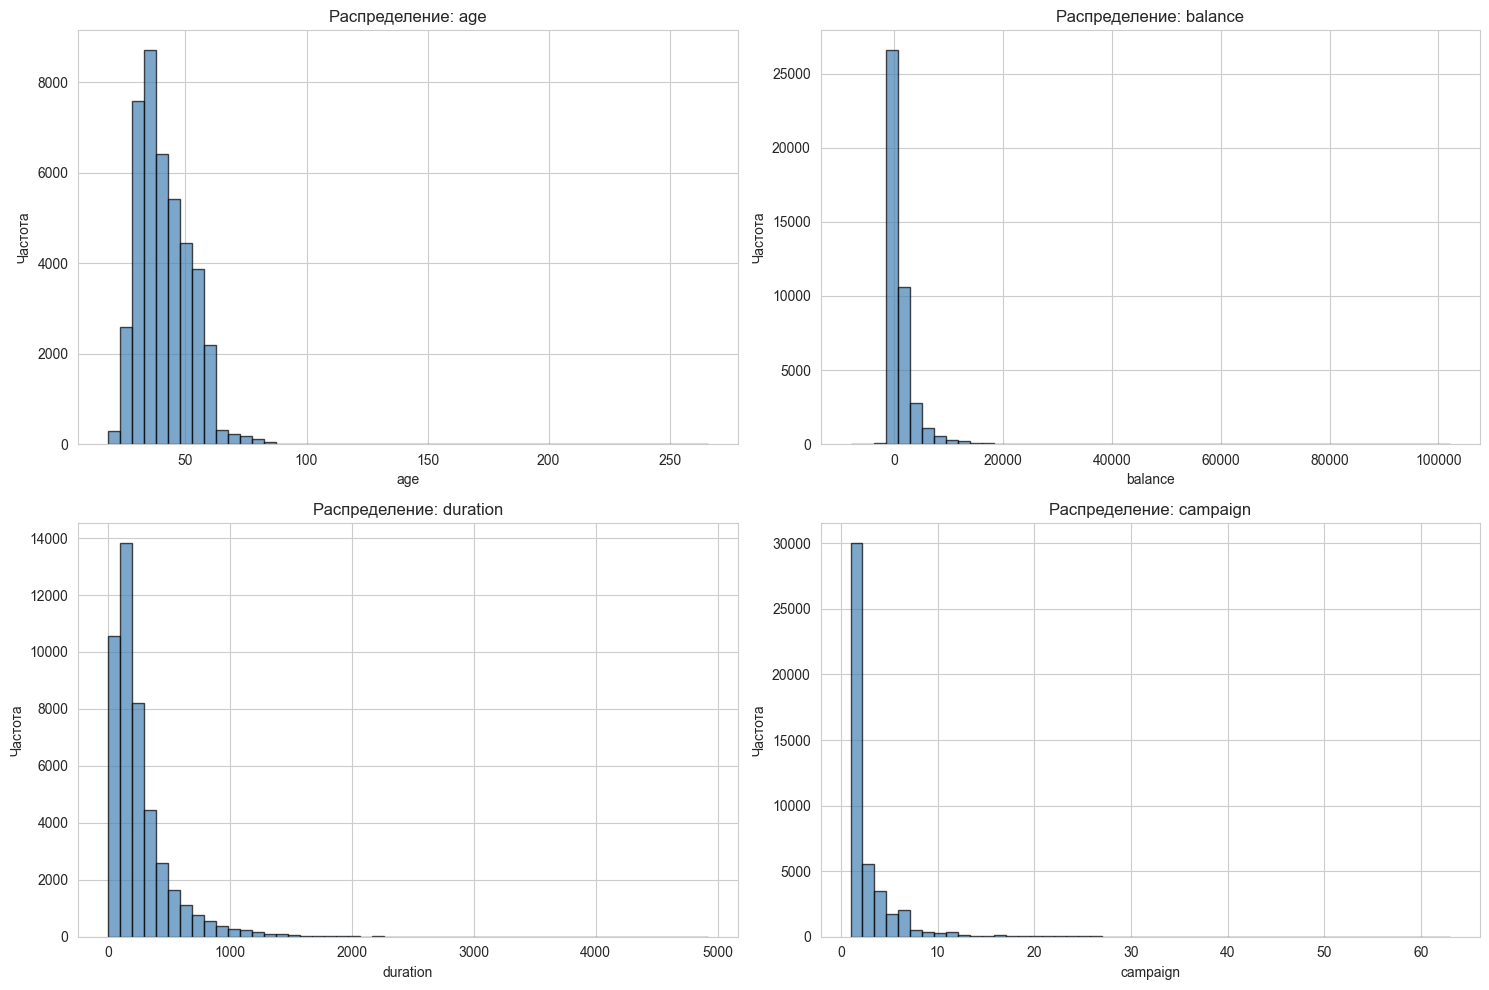

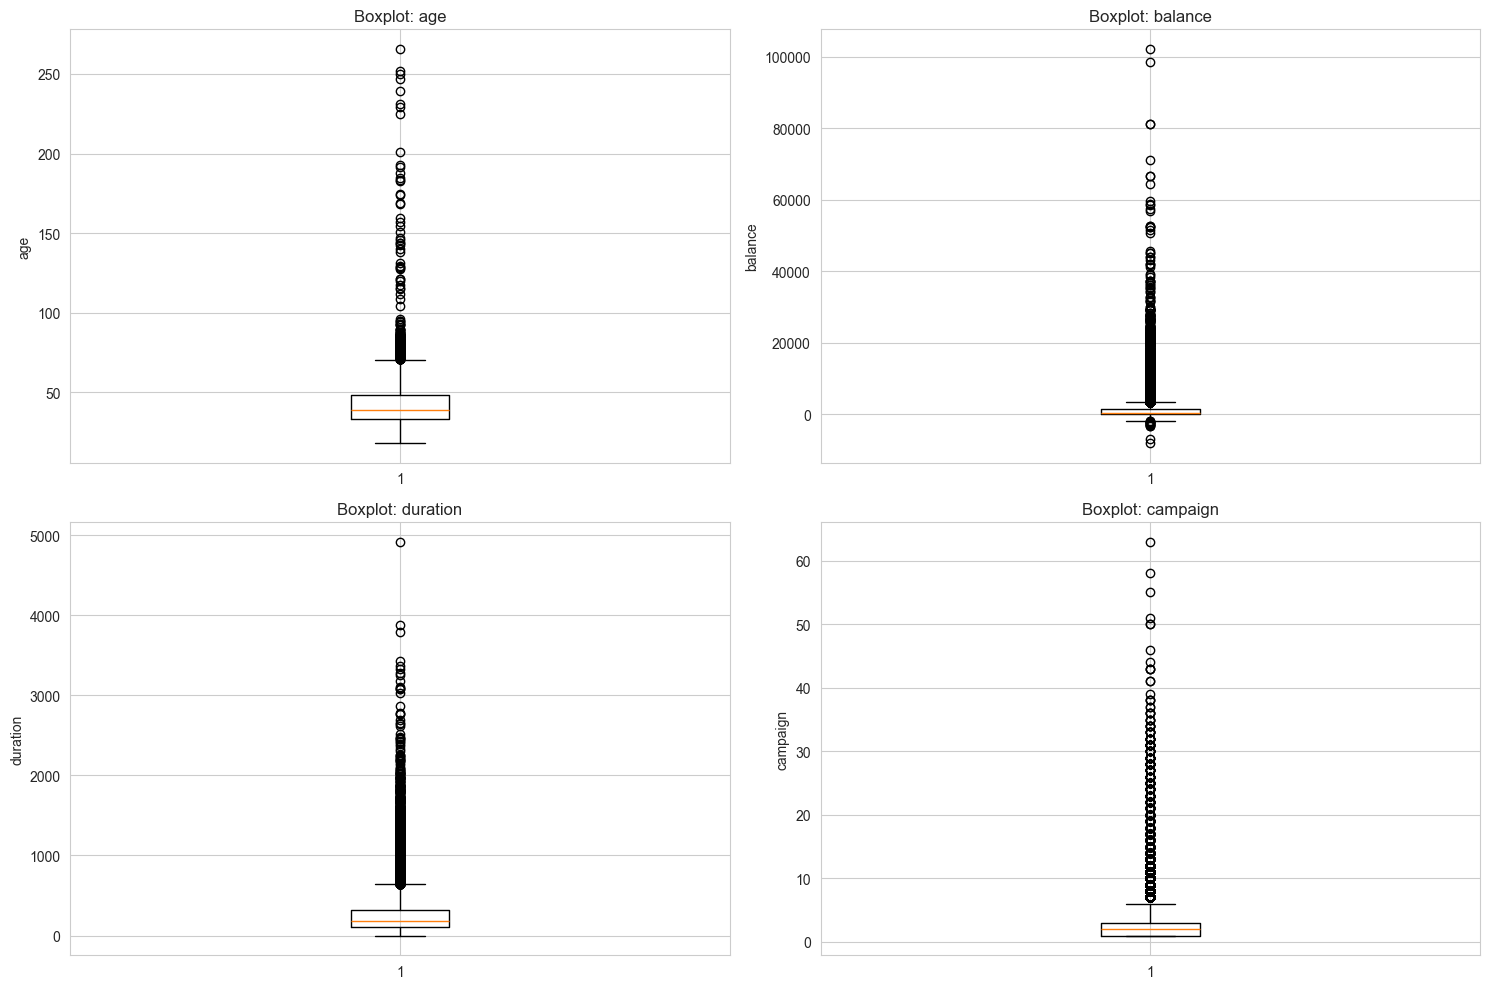

In [13]:
print("--- 6. Визуализация распределений числовых признаков ---")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()
numeric_cols = ['age', 'balance', 'duration', 'campaign']
for i, col in enumerate(numeric_cols[:6]):
    axes[i].hist(df_clean[col].dropna(), bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    axes[i].set_title(f'Распределение: {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Частота')

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(numeric_cols[:6]):
    axes[i].boxplot(df_clean[col].dropna(), vert=True)
    axes[i].set_title(f'Boxplot: {col}')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

Все предыдущие комментарии по переменным(когда рассматривали эксцесс и асимметрию) верны

**Выбросы удаление**

In [14]:
df['age'] = df['age'].clip(18, 100)
df['balance'] = df['balance'].clip(df['balance'].quantile(0.01), df['balance'].quantile(0.99))
print(f"age: [{df['age'].min():.0f}, {df['age'].max():.0f}] | balance: [{df['balance'].min():.0f}, {df['balance'].max():.0f}]")

age: [18, 100] | balance: [-625, 13227]


**Корреляционный анализ**

--- 7. Корреляционный анализ числовых признаков(Пирсон) ---


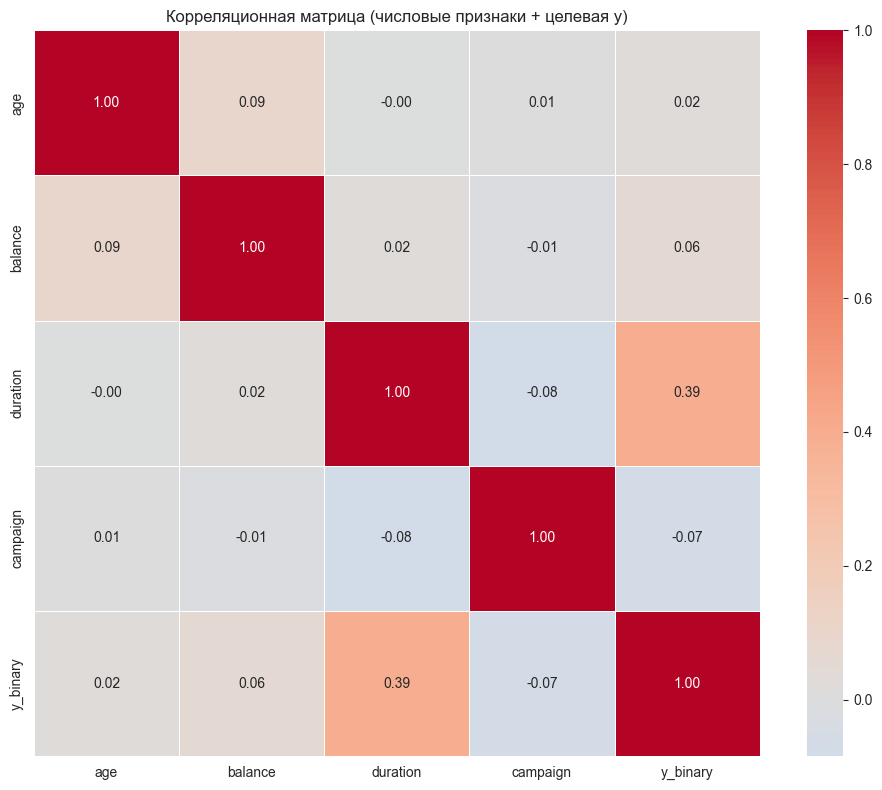

Корреляции с целевой переменной (y_binary):
duration    0.394
balance     0.056
age         0.023
campaign   -0.073
Name: y_binary, dtype: float64


In [15]:
print("--- 7. Корреляционный анализ числовых признаков(Пирсон) ---")

df_clean['y_binary'] = (df_clean['y'] == 'yes').astype(int)

corr_cols = numeric_cols + ['y_binary']
corr_matrix = df_clean[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, 
            fmt='.2f', square=True, linewidths=0.5)
plt.title('Корреляционная матрица (числовые признаки + целевая y)')
plt.tight_layout()
plt.show()

print("Корреляции с целевой переменной (y_binary):")
correlations = corr_matrix['y_binary'].drop('y_binary').sort_values(ascending=False)
print(correlations.round(3))


Умеренная корреляция наблюдается у целевой переменной, однако в самом описание к признакам написано: 	last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model. Следовательно, лучше не использовать этот признак при прогнозирование. Среди переменных почти вообще нет корреляции. Только у признаков: pdays, previous. 

--- 7.1. Ранговая корреляция Спирмена ---


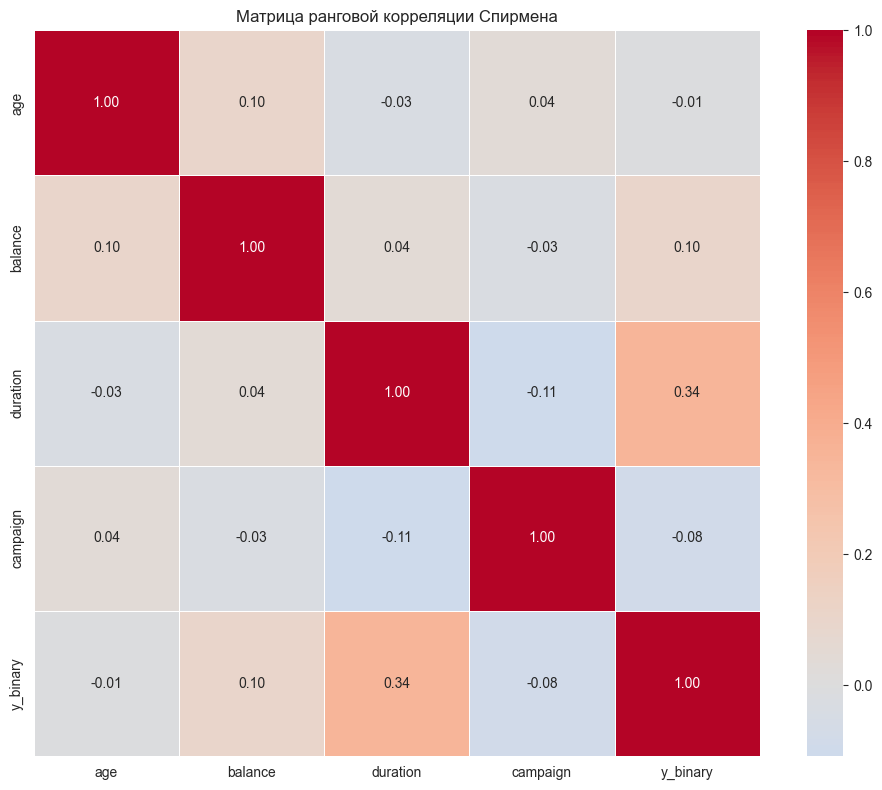

Корреляции Спирмена с целевой переменной:
duration    0.342
balance     0.102
age        -0.010
campaign   -0.084
Name: y_binary, dtype: float64

Сравнение Пирсон vs Спирмен:
          Pearson  Spearman
duration    0.394     0.342
balance     0.056     0.102
age         0.023    -0.010
campaign   -0.073    -0.084


In [16]:
print("--- 7.1. Ранговая корреляция Спирмена ---")

corr_cols = numeric_cols + ['y_binary']
spearman_matrix = df_clean[corr_cols].corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(spearman_matrix, annot=True, cmap='coolwarm', center=0,
            fmt='.2f', square=True, linewidths=0.5)
plt.title('Матрица ранговой корреляции Спирмена')
plt.tight_layout()
plt.show()

print("Корреляции Спирмена с целевой переменной:")
print(spearman_matrix['y_binary'].drop('y_binary').sort_values(ascending=False).round(3))

comparison = pd.DataFrame({
    'Pearson': df_clean[corr_cols].corr()['y_binary'],
    'Spearman': spearman_matrix['y_binary']
}).drop('y_binary')
print("\nСравнение Пирсон vs Спирмен:")
print(comparison.round(3).sort_values('Spearman', ascending=False))


Использовали Спирмена, так как есть выбросы в данных. Сравнение показывает, что Спирмен здесь чуть лучше улавливает связь, однако это не критично.

--- 7.2. Доля открывших вклад (конверсия) по категориям ---


C:\Users\Admin\AppData\Local\Temp\ipykernel_29688\3427708210.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=conversion.index, y=conversion.values, ax=axes[i], palette='Blues_r')
C:\Users\Admin\AppData\Local\Temp\ipykernel_29688\3427708210.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=conversion.index, y=conversion.values, ax=axes[i], palette='Blues_r')
C:\Users\Admin\AppData\Local\Temp\ipykernel_29688\3427708210.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=conversion.index, y=conversion.values, ax=axes[i], palette=

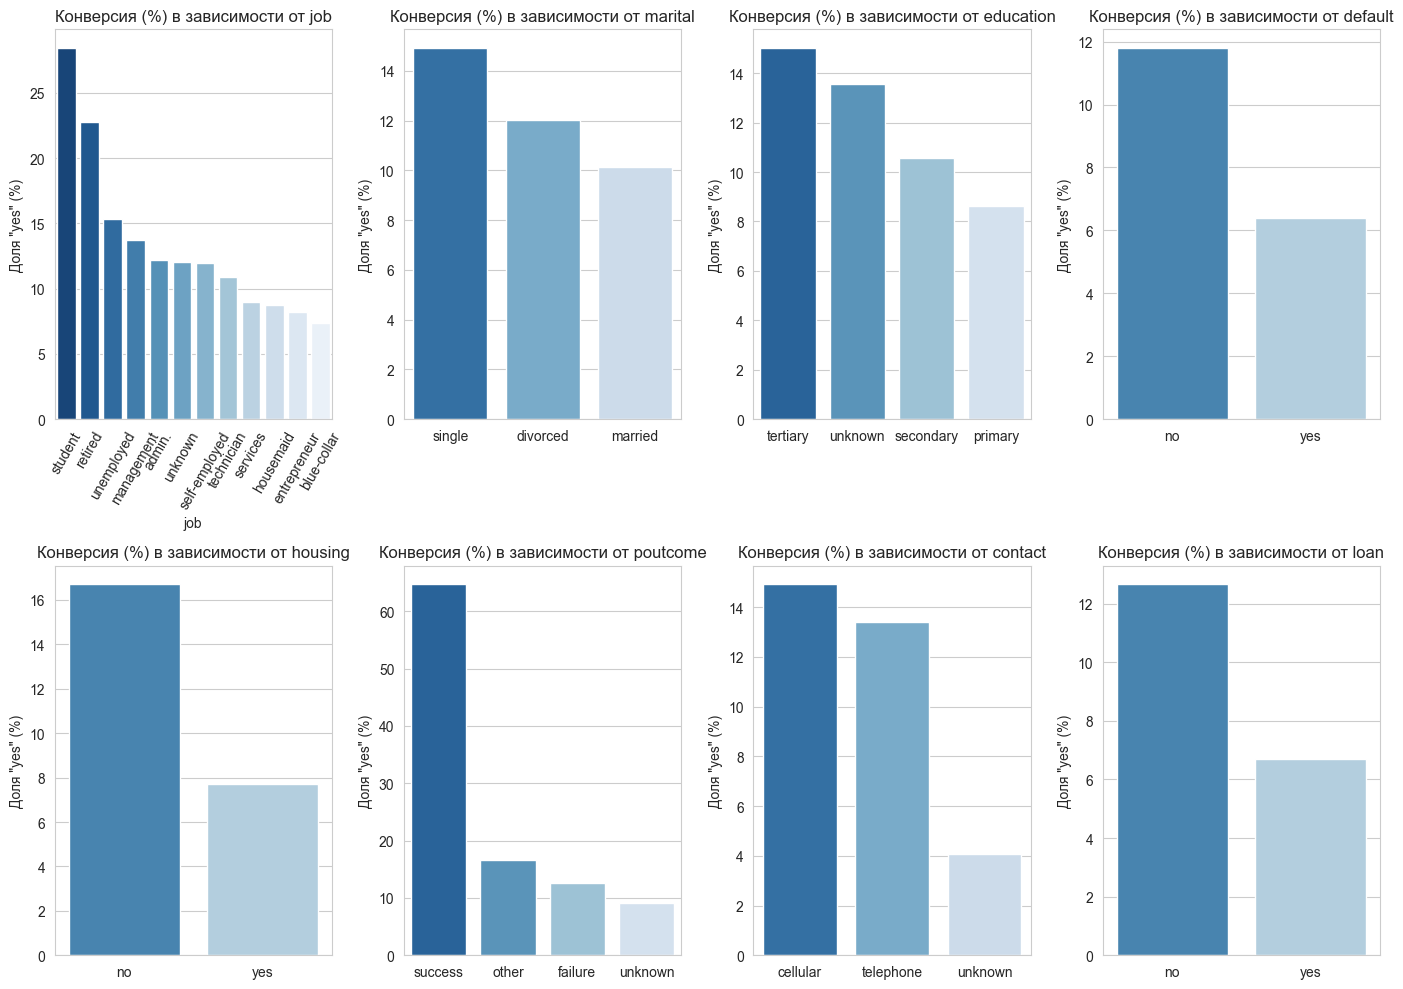

In [17]:
print("--- 7.2. Доля открывших вклад (конверсия) по категориям ---")

cat_analysis_cols = ['job','marital','education','default','housing','poutcome', 'contact', 'loan']
fig, axes = plt.subplots(2, 4, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cat_analysis_cols):
    if col == 'job':
        conversion = df_clean.groupby(col)['y_binary'].mean().sort_values(ascending=False) * 100
        sns.barplot(x=conversion.index, y=conversion.values, ax=axes[i], palette='Blues_r')
        axes[i].set_title(f'Конверсия (%) в зависимости от {col}')
        axes[i].set_ylabel('Доля "yes" (%)')
        axes[i].tick_params(axis='x', rotation=60) 
    else:
        conversion = df_clean.groupby(col)['y_binary'].mean().sort_values(ascending=False) * 100
        sns.barplot(x=conversion.index, y=conversion.values, ax=axes[i], palette='Blues_r')
        axes[i].set_title(f'Конверсия (%) в зависимости от {col}')
        axes[i].set_ylabel('Доля "yes" (%)')
        axes[i].set_xlabel('')
plt.tight_layout()
plt.show()


Здесь мы решили добавить также исследование категориальных данных, так как их зависимости(корреляции)очень важны. В основном люди которые одиноки берут депозиты. У людей, которых нет просрочек по кредитам чаще берут депозиты. Тоже самое с кредитами на дом. Также, очень интересно, люди, которые раньше участовали в компании и оформили депозит, в 65% случаев также оформляют депозит. С обычными кредитами также как и с кредитами на дом, в два раза чаще депозит оформляют те, у кого нет кредитов. Из этого точно можно сделать вывод что многие категориальные признаки очень важны и пропускать их при исследование признаков нельзя.

In [18]:
print("--- 7.3. V Крамера и хи-квадрат: связь категориальных признаков с y ---")

from scipy.stats import chi2_contingency

cat_features = ['job', 'marital', 'education', 'default', 'housing', 'loan',
                'contact', 'day', 'month', 'poutcome']

rows = []
for col in cat_features:
    ct = pd.crosstab(df_clean[col], df_clean['y'])
    chi2, p, dof, _ = chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))   # V Крамера
    rows.append([col, df_clean[col].nunique(), round(v, 3), round(chi2, 1), p])

v_table = pd.DataFrame(rows, columns=['Признак', 'Категорий', 'V Крамера', 'Хи-квадрат', 'p-value'])
print(v_table.sort_values('V Крамера', ascending=False).to_string(index=False))

--- 7.3. V Крамера и хи-квадрат: связь категориальных признаков с y ---
  Признак  Категорий  V Крамера  Хи-квадрат       p-value
 poutcome          4      0.312      4389.1  0.000000e+00
    month         12      0.261      3071.3  0.000000e+00
  contact          3      0.151      1037.1 6.114633e-226
  housing          2      0.139       875.3 2.276861e-192
      job         12      0.135       774.7 5.234451e-159
      day         31      0.113       574.4 5.833869e-102
education          4      0.073       240.5  7.239613e-52
     loan          2      0.068       210.0  1.363816e-47
  marital          3      0.065       181.8  3.385199e-40
  default          2      0.022        22.2  2.416814e-06


Использовали также хи-квадрат и Крамера ля того чтобы понять связь между категориальными данными и y. Видно, что признак "результат предыдущей маркетинговой кампании" показывает легкую связь с целевой переменой. Это также видно на таблице с конверсией. С success люди больше берут вклады.

**Сравнение распределений по целевой переменной**

--- Сравнение распределений числовых признаков по целевой переменной ---


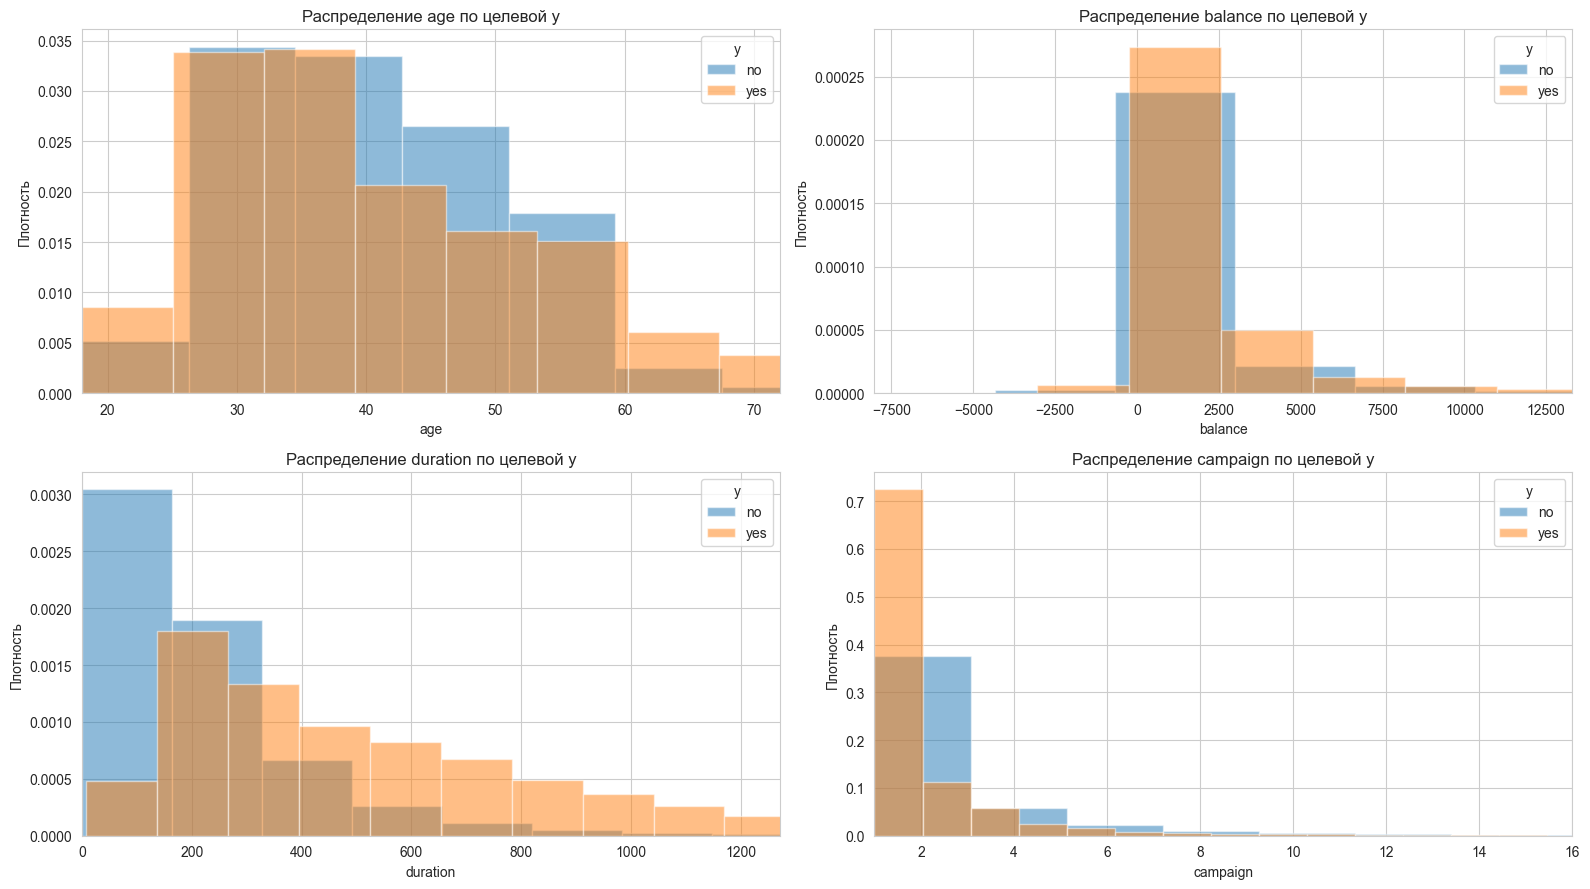


Медианы числовых признаков по классам y:
      age  balance  duration  campaign
y                                     
no   39.0    416.0     164.0       2.0
yes  38.0    751.0     426.0       2.0


In [19]:
print("--- Сравнение распределений числовых признаков по целевой переменной ---")

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    for y_class in ['no', 'yes']:
        subset = df_clean[df_clean['y'] == y_class][col].dropna()
        axes[i].hist(subset, bins=30, alpha=0.5, label=y_class, density=True)
    axes[i].set_title(f'Распределение {col} по целевой y')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Плотность')
    axes[i].set_xlim(df_clean[col].min(), df_clean[col].quantile(0.99))
    axes[i].legend(title='y')

plt.tight_layout()
plt.show()

print("\nМедианы числовых признаков по классам y:")
print(df_clean.groupby('y')[numeric_cols].median().round(1))


Видно, что 88.3% no против 11.7% yes. По возрасту конверсия: 18–25 → 23.7%, 25–45 → 9–12%, 55–65 → 14.0%, >65 → 41.0%.Дальше идет на спад. Интересно, что люди, у которых в районе 0 и до 3000 в банке денег, примерно одинаково кладут деньги в банк. Людей, с которыми меньше всего контактировали за время кампании, больше берут депозитов.

### 3.3 Выводы по итогам EDA

1. **Пропуски**: в 4 колонках по 6%(которые мы сами сделали), чтобы они не влияли на результата мы их обработаем не в EDA а уже когда будем заполнять в pipline. Числовые = медиана, категориальные = мода.

2. **Дубликаты**: 1799  удалены, датасет из 47 019 стал 45 220 строк.

3. **Выбросы**: во всех числовых полях. age — нереальный максимум 265.6 лет, удалить. У balance, duration, campaign заметные выбросы — для линейных моделей логарифмировать.

4. **Распределения**: age близко к нормальному (основная масса 33–48 лет), остальные сильно скошены вправо (balance 8.45, previous 41.85). duration — лучший разделитель: медиана 426 сек у yes против 164 у no. Но его лучше не использовать, так как это написано в самой аннотации к признакам. 

5. **Корреляции** Пирсон: duration +0.394/+0.342 — сильнейшая; pdays +0.104/+0.154; previous +0.093/+0.169; balance +0.056/+0.102; age +0.023/-0.010 (связи нет); campaign -0.073/-0.084. Крамер показывает связь признака poutcome с целевой.

6. **Баланс классов**: сильный дисбаланс — 88.3% no / 11.7% yes, нужны F1 и ROC-AUC. У категориальных тоже: default (no 98.2%), poutcome (unknown 81.8%), loan (no 84%).


# 4. Решение задачи классификации
## 4.1. Постановка задачи

**Тип задачи**: Бинарная классификация.

**Целевая переменная**: y = no (0) или y = yes (1).

**Метрика качества**: Основная — F1-score и ROC-AUC (из-за дисбаланса классов). Дополнительно — accuracy, precision, recall.

*Почему F1, а не accuracy?* Accuracy может быть обманчива при дисбалансе .
F1 учитывает и precision, и recall.*

## 4.2. Технология решения
**1. Предобработка**:
- Обработка пропусков (импутация).
- Кодирование категориальных признаков (One-Hot Encoding).
- Масштабирование числовых признаков (StandardScaler).
- Разделение на train/test (80/20).

**2. Применение моделей для сравнения**:
- Логистическая регрессия — базовая линейная модель.
- K-Nearest Neighbors - простой алгоритм, определяющий класс по большинству соседей.
- Support Vector Machine — алгоритм, проводящий максимально широкую границу между классами.

**3. Оценка**:
- Cross-validation для надёжности.
- Сравнение по F1, ROC-AUC, precision, recall.
- Confusion matrix для анализа ошибок.

## 4.3 Код решения

**Подключение библиотек**

In [ ]:
print("     ---  Решение задачи классификации  ---")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)

     ---  Решение задачи классификации  ---


Мы импортировали все необходимые библиотеки для машинного обучения. Ключевые компоненты:

1. Pipeline и ColumnTransformer: для автоматизации предобработки
2. SimpleImputer: для заполнения пропусков
3. StandardScaler: для масштабирования числовых признаков
4. OneHotEncoder: для кодирования категориальных признаков
5. Три модели: Logistic Regression (базовая), KNN, SVG
6. Метрики: accuracy, precision, recall, F1-score, ROC-AUC для комплексной оценки

Мы разделили данные на обучающую (80%, 36176 записи) и тестовую (20%, 9044 записи) выборки. Использование stratify=y гарантирует, что распределение классов в обеих выборках одинаковое (88% и 12%), что важно для корректной оценки модели. Целевая переменная преобразована в бинарный формат: 0 для no, 1 для yes. Дубликаты удалены на этапе предобработки.

**1: Предобработка данных**

In [21]:
df = pd.read_csv('bank-full-dirty.csv')
print(f"Размер загруженного датасета: {df.shape}")

n_duplicates = df.duplicated().sum()
print(f"Найдено полных дубликатов: {n_duplicates} ({n_duplicates / len(df) * 100:.2f}%)")

df = df.drop_duplicates().reset_index(drop=True)
print(f"Размер после удаления дубликатов: {df.shape}")

df['income'] = (df['y'] == 'yes').astype(int)
df = df.drop('y', axis=1)

numeric_features = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']
categorical_features = ['job', 'marital', 'education', 'default', 'housing', 'loan',
                        'contact', 'day', 'month', 'poutcome']

X = df[numeric_features + categorical_features]
y = df['income']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nTrain size: {X_train.shape}, Test size: {X_test.shape}")
print(f"Распределение классов в train: {y_train.value_counts(normalize=True).round(3)}")


Размер загруженного датасета: (47019, 17)
Найдено полных дубликатов: 1799 (3.83%)
Размер после удаления дубликатов: (45220, 17)

Train size: (36176, 16), Test size: (9044, 16)
Распределение классов в train: income
0    0.883
1    0.117
Name: proportion, dtype: float64


Мы разделили данные на обучающую (80%, 36176 записи) и тестовую (20%, 9044 записи) выборки. Использование stratify=y гарантирует, что распределение классов в обеих выборках одинаковое (88% и 12%), что важно для корректной оценки модели. Целевая переменная преобразована в бинарный формат: 0 для no, 1 для yes. Дубликаты удалены на этапе предобработки.

**2: Создание препроцессора (Pipeline)**

Формирование списка последовательных операций, выполняемых с данными, с указанием их настроек.

In [22]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

Мы создали конвейер предобработки с двумя ветками:

1. Числовые признаки: пропуски заполняются медианой, затем данные масштабируются StandardScaler. Это важно для линейных моделей и методов, основанных на расстояниях.
2. Категориальные признаки: пропуски заполняются модой, затем применяется One-Hot Encoding - каждая категория превращается в отдельный бинарный признак. Параметр handle_unknown='ignore' позволяет модели работать с новыми категориями в тестовых данных.
   
ColumnTransformer объединяет обе ветки в единый конвейер, что обеспечивает консистентность обработки train и test данных.

**3: Определение пула моделей**

Формирование списка можелей ML, которые будут построены на некотором датасете, с указанием их гиперпараметров.

In [23]:
models = {
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100, 
        learning_rate=0.1, 
        max_depth=3, 
        random_state=42
    ),
    
    'Linear SVM': CalibratedClassifierCV(
        LinearSVC(
            class_weight='balanced',
            max_iter=2000,
            random_state=42
        ),
        cv=3
    ),
    
    'XGBoost': XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        scale_pos_weight=10,
        random_state=42,
        n_jobs=-1,
        eval_metric='logloss'
    )
}

Мы выбрали три модели разной сложности:

1. Gradient Boosting: ансамблевая модель, последовательно строящая деревья решений, где каждое следующее исправляет ошибки предыдущего. Отлично улавливает нелинейные зависимости в табличных данных, а ограничение глубины (max_depth=3) предотвращает переобучение.
2. Linear SVM: линейный классификатор, ищущий разделяющую гиперплоскость с максимальным зазором. Работает значительно быстрее нелинейных аналогов, а параметр class_weight='balanced' автоматически компенсирует дисбаланс классов. Обёртка CalibratedClassifierCV добавляет возможность предсказания вероятностей для расчёта ROC-AUC.
3. XGBoost: оптимизированная и быстрая реализация градиентного бустинга с поддержкой параллельных вычислений (n_jobs=-1). Ключевой параметр scale_pos_weight=10 принудительно повышает вес миноритарного класса, что критически важно для корректного обучения на несбалансированных данных.

**4: Обучение и оценка моделей**

In [24]:
print("--- Обучение и оценка моделей ---")
results = {}

def find_optimal_threshold(y_true, y_prob):
    best_threshold, best_f1 = 0.5, 0
    for threshold in np.arange(0.1, 0.9, 0.01):
        f1_temp = f1_score(y_true, (y_prob >= threshold).astype(int), zero_division=0)
        if f1_temp > best_f1:
            best_f1, best_threshold = f1_temp, threshold
    return best_threshold, best_f1

for name, model in models.items():
    print(f"\n--- Применение модели {name} ---")
    
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
    pipeline.fit(X_train, y_train)
    
    y_proba = pipeline.predict_proba(X_test)[:, 1]
    
    opt_thresh, _ = find_optimal_threshold(y_test, y_proba)
    y_pred = (y_proba >= opt_thresh).astype(int)
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_proba)
    
    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='f1')
    
    results[name] = {
        'Accuracy': accuracy, 'Precision': precision, 'Recall': recall,
        'F1': f1, 'ROC-AUC': roc_auc, 'Optimal Threshold': opt_thresh,
        'CV F1 (mean)': cv_scores.mean(), 'CV F1 (std)': cv_scores.std()
    }
    
    print(f"  Accuracy:  {accuracy:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall:    {recall:.4f}")
    print(f"  F1-score:  {f1:.4f} (при пороге {opt_thresh:.2f})")
    print(f"  ROC-AUC:   {roc_auc:.4f}")
    print(f"  CV F1:     {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

--- Обучение и оценка моделей ---

--- Применение модели Gradient Boosting ---
  Accuracy:  0.8960
  Precision: 0.5432
  Recall:    0.6947
  F1-score:  0.6097 (при пороге 0.26)
  ROC-AUC:   0.9224
  CV F1:     0.5092 ± 0.0135

--- Применение модели Linear SVM ---
  Accuracy:  0.8894
  Precision: 0.5213
  Recall:    0.6711
  F1-score:  0.5868 (при пороге 0.21)
  ROC-AUC:   0.9101
  CV F1:     0.4528 ± 0.0055

--- Применение модели XGBoost ---
  Accuracy:  0.8910
  Precision: 0.5254
  Recall:    0.7051
  F1-score:  0.6021 (при пороге 0.76)
  ROC-AUC:   0.9208
  CV F1:     0.5247 ± 0.0074


Мы решили сделать разные пороги, чтобы мы смогли понять при каком случае у нас лучше всего выходит F1-Score  раз мы ее определили как основую для принятия решений о качестве моделей. 
- Gradient Boosting: F1=0.6097, ROC-AUC=0.9224. Лучший F1-score среди всех моделей. Ансамбль деревьев последовательно исправляет ошибки предыдущих итераций, что позволяет эффективно работать с дисбалансом классов. Оптимальный порог классификации составил 0.26, что значительно ниже стандартного 0.5 и подтверждает смещённость модели в сторону мажоритарного класса.
- Linear SVM: F1=0.5868, ROC-AUC=0.9101. Линейный классификатор с калибровкой вероятностей показал наименьший F1-score, но при этом продемонстрировал наивысшую стабильность при кросс-валидации (std=0.0055). Оптимальный порог 0.21 — самый низкий среди моделей, что говорит о консервативности прогнозов вероятностей.
- XGBoost: F1=0.6021, ROC-AUC=0.9208. Современная реализация градиентного бустинга показала результаты, сопоставимые с классическим Gradient Boosting. Оптимальный порог классификации составил 0.76 — единственный случай, когда порог пришлось повысить выше стандартного значения, что связано с агрессивным влиянием параметра scale_pos_weight=10, заставившего модель слишком часто предсказывать положительный класс.

**5: Сравнение моделей**


СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ

                   Accuracy  Precision  Recall      F1  ROC-AUC  \
Gradient Boosting    0.8960     0.5432  0.6947  0.6097   0.9224   
Linear SVM           0.8894     0.5213  0.6711  0.5868   0.9101   
XGBoost              0.8910     0.5254  0.7051  0.6021   0.9208   

                   Optimal Threshold  CV F1 (mean)  CV F1 (std)  
Gradient Boosting               0.26        0.5092       0.0135  
Linear SVM                      0.21        0.4528       0.0055  
XGBoost                         0.76        0.5247       0.0074  


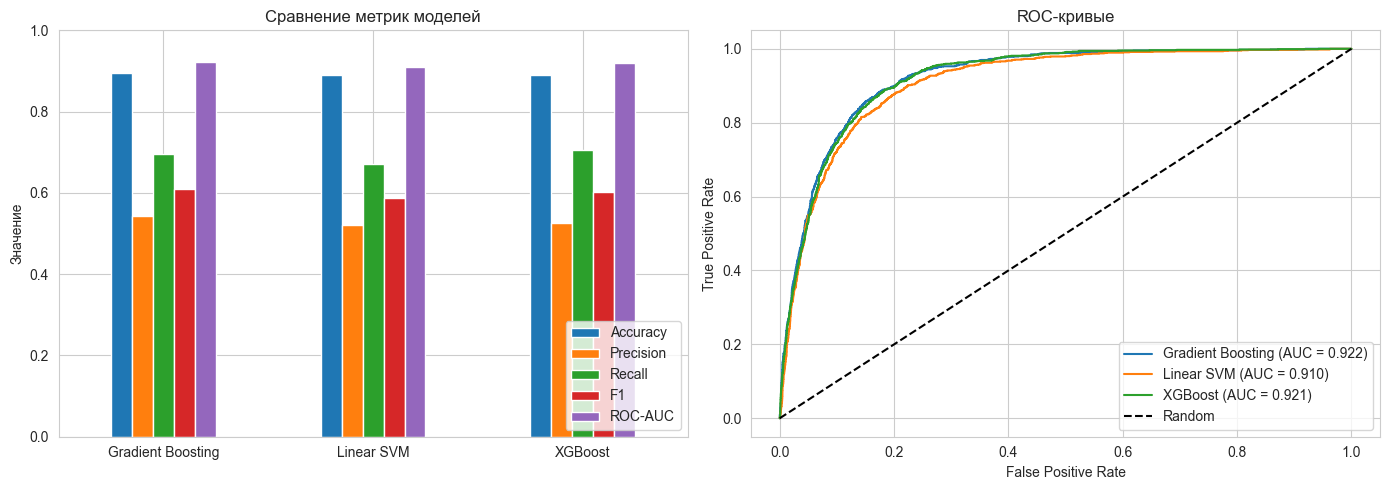

In [ ]:
results_df = pd.DataFrame(results).T

print("\nСВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ\n")
print(results_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

results_df[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']].plot(
    kind='bar', ax=axes[0], rot=0
)
axes[0].set_title('Сравнение метрик моделей')
axes[0].set_ylabel('Значение')
axes[0].legend(loc='lower right')
axes[0].set_ylim(0, 1)

# ROC curves
for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    pipeline.fit(X_train, y_train)
    y_proba = pipeline.predict_proba(X_test)[:, 1]
    
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    axes[1].plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

axes[1].plot([0, 1], [0, 1], 'k--', label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC-кривые')
axes[1].legend()

plt.tight_layout()
plt.show()

Сводная таблица и визуализации позволяют сделать следующие выводы:
По F1-score: Gradient Boosting (0.6097) > XGBoost (0.6021) > Linear SVM (0.5868).
По ROC-AUC: Gradient Boosting (0.9224) > XGBoost (0.9208) > Linear SVM (0.9101).
Precision vs Recall: все модели имеют близкие значения precision (0.52–0.54), но XGBoost показал наивысший recall (0.7051) за счёт высокого порога классификации (0.76), что связано с агрессивным параметром scale_pos_weight=10. Gradient Boosting с порогом 0.26 демонстрирует более сбалансированный результат.
ROC-кривые: все три модели значительно выше диагонали случайного классификатора, что подтверждает их эффективность. Кривые Gradient Boosting и XGBoost практически совпадают и слегка превосходят Linear SVM в области низкого FPR.
Стабильность (CV F1): Linear SVM показал наименьшее стандартное отклонение (0.0055), что говорит о его высокой устойчивости, тогда как Gradient Boosting имеет наибольший разброс (0.0135).
Gradient Boosting выбран как лучшая модель по совокупности метрик F1-score и ROC-AUC, что наиболее важно при работе с несбалансированными данными.

### Модели показали близкое качество классификации с небольшим преимуществом Gradient Boosting


Лучшая модель по F1: Gradient Boosting


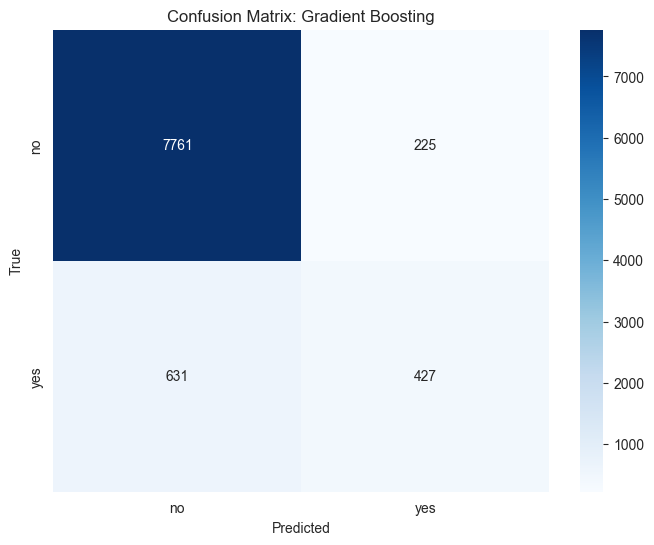


Оценки качества классификации лучшей модели

              precision    recall  f1-score   support

          no       0.92      0.97      0.95      7986
         yes       0.65      0.40      0.50      1058

    accuracy                           0.91      9044
   macro avg       0.79      0.69      0.72      9044
weighted avg       0.89      0.91      0.90      9044



In [ ]:
best_model_name = results_df['F1'].idxmax()
print(f"\nЛучшая модель по F1: {best_model_name}")

best_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', models[best_model_name])
])
best_pipeline.fit(X_train, y_train)
y_pred_best = best_pipeline.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['no', 'yes'], 
            yticklabels=['no', 'yes'])
plt.title(f'Confusion Matrix: {best_model_name}')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.show()

print("\nОценки качества классификации лучшей модели\n")
print(classification_report(y_test, y_pred_best, 
                           target_names=['no', 'yes']))

Матрица ошибок:
True Negatives (7,761): правильно предсказан класс «no»
True Positives (427): правильно предсказан класс «yes»
False Positives (225): ошибочно предсказан «yes» вместо «no»
False Negatives (631): ошибочно предсказан «no» вместо «yes»
Classification Report:
Класс no: precision=0.92, recall=0.97, F1=0.95 — модель отлично работает с мажоритарным классом
Класс yes: precision=0.65, recall=0.40, F1=0.50 — качество заметно ниже из-за дисбаланса
Общая accuracy: 0.91 — высокий показатель, но вводит в заблуждение из-за дисбаланса классов
Модель хорошо распознаёт класс «no» (recall=0.97), но пропускает 60% объектов класса «yes» (recall=0.40).

**7: Интерпретация (важность признаков для Gradient Boosting)**

C:\Users\Admin\AppData\Local\Temp\ipykernel_29688\3604764576.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importances, x='importance', y='feature', palette='viridis')


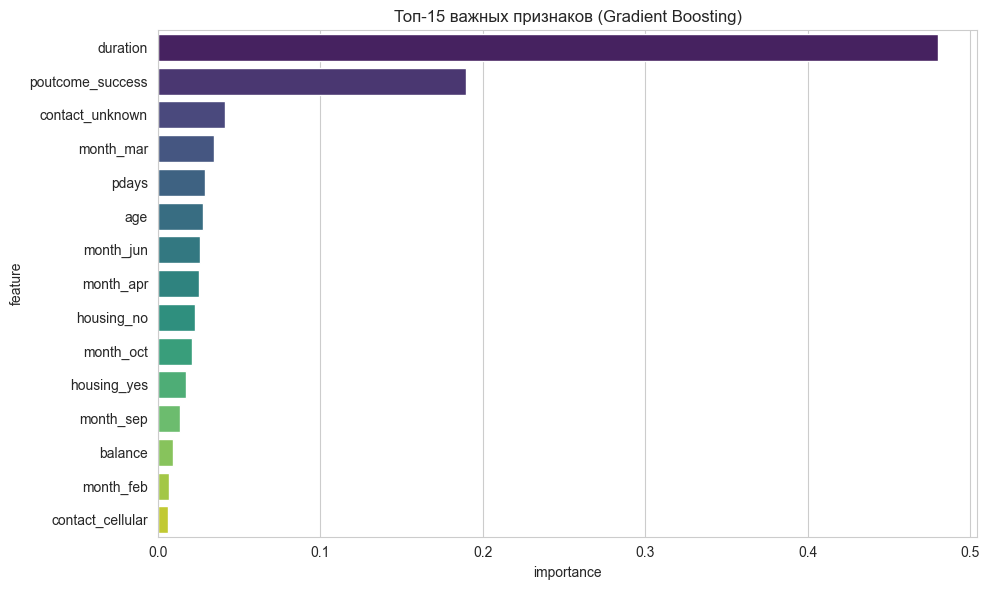


Топ-10 важных признаков:
         feature  importance
        duration    0.480463
poutcome_success    0.189658
 contact_unknown    0.041325
       month_mar    0.034308
           pdays    0.029277
             age    0.027665
       month_jun    0.026122
       month_apr    0.025514
      housing_no    0.022763
       month_oct    0.020944


In [ ]:
if best_model_name == 'Gradient Boosting':
    gb_model = best_pipeline.named_steps['classifier']
    feature_names = (numeric_features + 
                     list(best_pipeline.named_steps['preprocessor']
                          .named_transformers_['cat']
                          .named_steps['onehot']
                          .get_feature_names_out(categorical_features)))
    
    importances = pd.DataFrame({
        'feature': feature_names,
        'importance': gb_model.feature_importances_
    }).sort_values('importance', ascending=False).head(15)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(data=importances, x='importance', y='feature', palette='viridis')
    plt.title('Топ-15 важных признаков (Gradient Boosting)')
    plt.tight_layout()
    plt.show()
    
    print("\nТоп-10 важных признаков:")
    print(importances.head(10).to_string(index=False))

Что мы сделали в этой лабораторной:
1. Создали датасет: искусственно внесли в исходные данные банка 6% пропусков, 4% дубликатов и выбросы в числовые признаки, чтобы смоделировать реальные условия работы с данными.
2. Провели разведочный анализ (EDA):
Выявили сильный дисбаланс классов (88.3% «no» против 11.7% «yes»).
Обнаружили сильные выбросы и правостороннюю асимметрию в признаках balance, duration и campaign.
3. Подготовили данные: удалили дубликаты и создали единый Pipeline, который автоматически заполняет пропуски (медианой для чисел, модой для категорий), масштабирует числовые признаки (StandardScaler) и кодирует категориальные (OneHotEncoder).
4. Обучили и сравнили три модели: Gradient Boosting, Linear SVM и XGBoost. Для борьбы с дисбалансом использовали подбор оптимального порога классификации. Gradient Boosting показал лучший результат (F1-score = 0.6097, ROC-AUC = 0.9224).
5. Проанализировали ошибки лучшей модели: общая точность (Accuracy) высока (91%), но из-за дисбаланса модель пропускает 60% реальных клиентов, согласившихся на вклад.
6. Изучили важность признаков.

- Как обработка пропусков повлияла на качество модели? Что было бы, если их просто удалить?
Влияние: Заполнение пропусков позволило сохранить полный объем выборки и информационную ценность данных. Это обеспечило модели достаточное количество примеров для обучения, что положительно сказалось на её стабильности и итоговых метриках (F1-score).
Если удалить: У нас было 4 колонки с 6% пропусков. При простом удалении строк мы бы потеряли значительную часть датасета. Потеря данных привела бы к уменьшению обучающей выборки, росту дисперсии модели, ухудшению обобщающей способности и, как следствие, к падению качества предсказаний (особенно для миноритарного класса «yes»).
- Что произойдёт с моделью, если не масштабировать числовые признаки перед логистической регрессией?
Искусственное доминирование признаков: Логистическая регрессия назначает веса признакам, исходя из их числовых значений. Признаки с большим разбросом (например, balance от -8000 до 100000) будут искусственно считаться моделью более важными, чем признаки с малым разбросом (например, age от 18 до 100), что исказит реальную картину.